<a href="https://colab.research.google.com/github/Renato7373/GS_SERS/blob/main/GS_SERS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ⚡ Citizen Assist AI — Módulo de Energia e Sustentabilidade
**Global Solution 2026 · Soluções em Energias Renováveis e Sustentáveis · Ciência da Computação (1CCPJ)**

**Integrantes:** `Conrado Gracie — 569157` · `Renato Sandreschi — 569156` ·

> Este notebook é a contribuição da disciplina ao Citizen Assist AI: define o público, analisa o consumo, compara alternativas (eficiência × solar fotovoltaica), integra os resultados a um assistente e gera os arquivos do repositório (README, dados, referências e testes).
>


## 1. Definição do contexto

| Item | Descrição |
|---|---|
| **Público** | Famílias de baixa renda em moradias urbanas na Grande São Paulo (ex.: Santo André/SP), 4 pessoas, ligação monofásica, conta de energia como um dos maiores gastos fixos. |
| **Necessidade energética** | Reduzir o valor da conta de luz sem perder conforto, entendendo **onde a energia é gasta** e **o que compensa fazer primeiro**. |
| **Como o assistente ajuda** | Responde em linguagem simples: quanto cada aparelho gasta, quanto se economiza com cada medida, quanto custa, em quanto tempo se paga e quais as limitações. |
| **Alternativas comparadas** | **A)** Eficiência energética e uso consciente (LED, banho, *stand-by*) · **B)** Energia solar fotovoltaica (fonte renovável) · **C)** Combinação A + B. |
| **Período de referência comum** | 1 mês (consumo/economia) e 25 anos (retorno financeiro). |

⚠️ **Todos os dados de consumo da residência são ESTIMADOS** (perfil típico), conforme exigido pelo enunciado: devem ser identificados como estimativas e substituídos por dados reais do usuário quando disponíveis (conta de luz).

## 2. Premissas e dados (origem, unidades, período)
**Classificação:** `PÚBLICO` (fonte verificável) · `CALCULADO` (derivado de dados públicos) · `ESTIMADO` (estimativa justificada) · `HIPÓTESE` (suposição do perfil). **Período de referência:** 1 mês (30 dias) e 25 anos. **Consulta às fontes:** 12/11/2026. Os consumos por aparelho são **todos estimados**; substitua pelos dados reais da conta de luz do usuário quando possível.

In [ ]:
import unicodedata, re, os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.options.display.float_format = '{:,.2f}'.format

# Legenda da classificação de cada dado:
#   [PÚBLICO]   = valor extraído de fonte pública verificável (fonte indicada)
#   [CALCULADO] = derivado de dados públicos por conta explícita
#   [ESTIMADO]  = estimativa justificada (faixa/ordem de grandeza), SUBSTITUA por dado real do usuário quando houver
#   [HIPÓTESE]  = suposição de uso/projeto do perfil de família adotado
# Data da consulta às fontes: 12/11/2026

# ================= PREMISSAS GERAIS =================
DIAS_MES = 30                      # [HIPÓTESE] período de referência mensal: 30 dias

# ---- Tarifa (R$/kWh, com tributos, TUSD+TE) ----
TUSD_AGO25   = 0.55565             # [PÚBLICO] R$/kWh c/ tributos – fatura Enel SP (monofásica, 262 kWh, ago/2025)
TE_AGO25     = 0.37607             # [PÚBLICO] R$/kWh c/ tributos – mesma fatura
REAJ_ENEL26  = 0.1018              # [PÚBLICO] reajuste tarifário médio Enel SP, vigência 04/07/2026 (efeito MÉDIO, não específico da classe B1)
TARIFA       = round((TUSD_AGO25 + TE_AGO25) * (1 + REAJ_ENEL26), 2)   # [CALCULADO] ≈ R$ 1,03/kWh (sem bandeira tarifária)
CUSTO_DISP   = 30                  # [PÚBLICO] kWh/mês – mínimo faturável monofásico (REN ANEEL 1000/2021; confirmado em fatura de 30 kWh)

# ---- Solar fotovoltaica ----
HSP          = 4.3                 # [ESTIMADO] kWh/m².dia (= horas de sol pleno). Faixa 4,1–4,6 p/ Grande SP: ~4,1 em material USP (AMT São Paulo) e ~4,5 típico de SunData. CONFIRMAR no SunData (lat/long da casa)
PR           = 0.78                # [ESTIMADO] taxa de desempenho (perdas de inversor, temperatura, sujeira, cabos). Faixa típica de engenharia 0,75–0,85
CUSTO_KWP    = 4500.0              # [ESTIMADO] R$/kWp instalado p/ sistema pequeno (~2 kWp). Referências: média nacional R$ 2,45/Wp (Solfácil, 1T/2026); Greener: 4 kWp = R$ 2,84/Wp (jun/2025); sistemas de 1,5–3 kWp: R$ 10–18 mil (Monitor do Mercado, 2026). Sistemas menores têm R$/Wp maior.
FIOB_PCT_2026 = 0.60               # [PÚBLICO] Lei 14.300/2022: em 2026 cobra-se 60% do "Fio B" sobre a energia injetada
FRAC_INJETADA = 0.70               # [HIPÓTESE] fração da geração injetada na rede (família fora de casa de dia)
FIOB_NA_TARIFA = 0.25              # [ESTIMADO] fração do valor da tarifa correspondente ao Fio B
FATOR_COMP   = round(1 - FRAC_INJETADA*FIOB_NA_TARIFA*FIOB_PCT_2026, 3)   # [CALCULADO] fração da tarifa efetivamente economizada ≈ 0,90
DEGRADACAO   = 0.005               # [ESTIMADO] perda anual de geração (0,5%/ano; típico de fabricantes de módulos)
ANOS         = 25                  # [ESTIMADO] vida útil dos módulos (garantias típicas 25 anos)
TROCA_INV_ANO = 12                 # [ESTIMADO] ano de troca do inversor
TROCA_INV_PCT = 0.12               # [ESTIMADO] custo da troca = 12% do investimento inicial
REAJUSTE_TAR = 0.04                # [ESTIMADO] reajuste médio anual da tarifa (4% a.a.). Conservador: Enel SP reajustou +13,94% (2025) e +10,18% (2026)

# ---- Emissões (kg CO2e por kWh) ----
FE_REDE      = 0.0385              # [PÚBLICO] fator médio anual do SIN em 2023 (MCTI): 0,0385 tCO2/MWh = 0,0385 kgCO2/kWh. (Em jan–abr/2025 o fator mensal ficou entre 0,0215 e 0,0289)
FE_FV_CICLO  = 0.041               # [ESTIMADO] ciclo de vida FV em telhado ≈ 41 gCO2e/kWh (IPCC AR5, Anexo III, mediana) – CONFERIR

# ---- Medidas de eficiência (alternativa A) ----
LED_W         = 9                  # [ESTIMADO] W – LED 9 W substitui incandescente 60 W (equivalência luminosa usual)
LED_CUSTO     = 8.0                # [ESTIMADO] R$ por lâmpada LED
STANDBY_NOVO  = 1                  # [ESTIMADO] W após usar régua com chave
REGUA_CUSTO   = 40.0               # [ESTIMADO] R$ por régua com interruptor
REDUCAO_BANHO = 0.25               # [HIPÓTESE] banho de 8 min -> 6 min (-25%)

### Registro de dados e premissas (origem · unidade · período · classificação)
A tabela abaixo é gerada automaticamente a partir das variáveis da célula anterior e é exportada para o repositório (`dados/premissas_origem.csv`).

In [ ]:
premissas = pd.DataFrame([
 ["Tarifa (TUSD+TE, c/ tributos) ago/2025", TUSD_AGO25+TE_AGO25, "R$/kWh", "ago/2025", "Fatura pública de unidade residencial monofásica da Enel SP (262 kWh) — camara.leg.br, cota parlamentar", "PÚBLICO"],
 ["Reajuste tarifário Enel SP 2026", REAJ_ENEL26*100, "%", "vigência 04/07/2026", "ANEEL, reajuste anual Enel SP (efeito médio 10,18%) — noticiado por Cenário Energia / Estadão", "PÚBLICO"],
 ["Tarifa adotada", TARIFA, "R$/kWh", "nov/2026 (sem bandeira)", "(TUSD+TE ago/2025) × (1+reajuste 2026)", "CALCULADO"],
 ["Custo de disponibilidade monofásico", CUSTO_DISP, "kWh/mês", "vigente", "REN ANEEL 1000/2021; fatura pública de 30 kWh monofásico (Enel SP, jul/2025)", "PÚBLICO"],
 ["Irradiação / HSP", HSP, "kWh/m².dia (média anual)", "média anual", "Faixa 4,1–4,6 (material USP/AMT SP; SunData/CRESESB). Valor central escolhido; confirmar no SunData", "ESTIMADO"],
 ["Taxa de desempenho (PR)", PR, "adimensional", "média anual", "Faixa típica de projeto FV (0,75–0,85)", "ESTIMADO"],
 ["Custo do sistema FV pequeno", CUSTO_KWP, "R$/kWp", "2025–2026", "Solfácil (R$ 2,45/Wp média nacional 1T/2026), Greener (4 kWp = R$ 2,84/Wp, jun/2025), Monitor do Mercado (1,5–3 kWp = R$ 10–18 mil, 2026)", "ESTIMADO"],
 ["Fio B sobre energia injetada", FIOB_PCT_2026*100, "%", "2026", "Lei 14.300/2022 (escalonamento; 60% em 2026)", "PÚBLICO"],
 ["Fração injetada na rede", FRAC_INJETADA, "adimensional", "média anual", "Perfil: família ausente de dia", "HIPÓTESE"],
 ["Peso do Fio B na tarifa", FIOB_NA_TARIFA, "adimensional", "—", "Ordem de grandeza; conferir na conta/ANEEL da distribuidora", "ESTIMADO"],
 ["Fator de compensação", FATOR_COMP, "adimensional", "2026", "1 − fração injetada × peso Fio B × 60%", "CALCULADO"],
 ["Degradação dos módulos", DEGRADACAO*100, "% ao ano", "25 anos", "Valor típico de garantias de fabricantes", "ESTIMADO"],
 ["Reajuste anual da tarifa", REAJUSTE_TAR*100, "% ao ano", "25 anos", "Premissa conservadora frente aos reajustes recentes da Enel SP (13,94% em 2025; 10,18% em 2026)", "ESTIMADO"],
 ["Fator de emissão do SIN", FE_REDE, "kgCO2/kWh", "média anual 2023", "MCTI (SIRENE) — 0,0385 tCO2/MWh", "PÚBLICO"],
 ["Emissão ciclo de vida FV", FE_FV_CICLO, "kgCO2e/kWh", "vida útil", "IPCC AR5 WGIII Anexo III (mediana, FV de telhado)", "ESTIMADO"],
 ["Potências dos aparelhos", np.nan, "W", "—", "Faixas típicas Procel/INMETRO (tabela de potências); ver coluna 'origem' na tabela de consumo", "ESTIMADO"],
 ["Tempo de uso dos aparelhos", np.nan, "h/dia; dias/mês", "30 dias", "Hipóteses de uso de família de 4 pessoas (ex.: 4 banhos × 8 min, TV 5 h/dia)", "HIPÓTESE"],
], columns=["Parâmetro","Valor","Unidade","Período/referência","Origem / justificativa","Classificação"])
premissas

,Parâmetro,Valor,Unidade,Período/referência,Origem / justificativa,Classificação
0,"Tarifa (TUSD+TE, c/ tributos) ago/2025",0.93,R$/kWh,ago/2025,Fatura pública de unidade residencial monofási...,PÚBLICO
1,Reajuste tarifário Enel SP 2026,10.18,%,vigência 04/07/2026,"ANEEL, reajuste anual Enel SP (efeito médio 10...",PÚBLICO
2,Tarifa adotada,1.03,R$/kWh,nov/2026 (sem bandeira),(TUSD+TE ago/2025) × (1+reajuste 2026),CALCULADO
3,Custo de disponibilidade monofásico,30.00,kWh/mês,vigente,REN ANEEL 1000/2021; fatura pública de 30 kWh ...,PÚBLICO
4,Irradiação / HSP,4.30,kWh/m².dia (média anual),média anual,"Faixa 4,1–4,6 (material USP/AMT SP; SunData/CR...",ESTIMADO
5,Taxa de desempenho (PR),0.78,adimensional,média anual,"Faixa típica de projeto FV (0,75–0,85)",ESTIMADO
6,Custo do sistema FV pequeno,"4,500.00",R$/kWp,2025–2026,"Solfácil (R$ 2,45/Wp média nacional 1T/2026), ...",ESTIMADO
7,Fio B sobre energia injetada,60.00,%,2026,Lei 14.300/2022 (escalonamento; 60% em 2026),PÚBLICO
8,Fração injetada na rede,0.70,adimensional,média anual,Perfil: família ausente de dia,HIPÓTESE
9,Peso do Fio B na tarifa,0.25,adimensional,—,Ordem de grandeza; conferir na conta/ANEEL da ...,ESTIMADO


In [ ]:
# Perfil de consumo ESTIMADO de uma família de 4 pessoas (potências típicas Procel/INMETRO; horas = hipóteses)
# Fórmula: Energia (kWh) = Potência (kW) x tempo (h)
equip = pd.DataFrame([
    # nome, W, h/dia, dias/mês, qtd, fator_ciclo, tipo, origem
    ["Chuveiro elétrico (4 pessoas x 8 min)", 5500, 32/60, 30, 1, 1.0, "ESTIMADO", "Potência típica 4.400–7.700 W (tabela de potências, Procel/INMETRO); 4 banhos x 8 min = hipótese"],
    ["Geladeira antiga (compressor, ciclo 50%)", 150, 24, 30, 1, 0.5, "ESTIMADO", "Potência 100–400 W (Procel/INMETRO); compressor liga ~50% do tempo (hipótese p/ modelo antigo)"],
    ["Lâmpadas incandescentes 60 W", 60, 5, 30, 6, 1.0, "HIPÓTESE", "6 lâmpadas, 5 h/dia (hipótese de uso residencial)"],
    ["TV", 100, 5, 30, 1, 1.0, "ESTIMADO", "100 W, 5 h/dia (casa-modelo ValorFinal, com dados Procel)"],
    ["Ferro de passar", 1000, 1, 8, 1, 1.0, "ESTIMADO", "1.000–1.800 W (Procel/INMETRO); 8 h/mês"],
    ["Máquina de lavar", 500, 1, 12, 1, 1.0, "ESTIMADO", "500 W, 1 h por ciclo (tabela de potências); 12 ciclos/mês = hipótese"],
    ["Ventilador", 80, 6, 30, 1, 1.0, "HIPÓTESE", "80 W, 6 h/dia"],
    ["Roteador/Wi-Fi", 10, 24, 30, 1, 1.0, "HIPÓTESE", "10 W, ligado 24 h"],
    ["Stand-by (carregadores, TV, decoder)", 8, 24, 30, 1, 1.0, "HIPÓTESE", "8 W somados, 24 h"],
], columns=["equipamento","potencia_W","horas_dia","dias_mes","qtd","fator_ciclo","tipo","origem"])

def kwh_mes(df):
    return df.potencia_W/1000 * df.horas_dia * df.dias_mes * df.qtd * df.fator_ciclo

equip["kWh_mes"]  = kwh_mes(equip)
equip["R$_mes"]   = equip.kWh_mes * TARIFA
equip["%"]        = 100*equip.kWh_mes/equip.kWh_mes.sum()

CONSUMO_BASE = equip.kWh_mes.sum()
CUSTO_BASE   = CONSUMO_BASE*TARIFA
print(f"[ESTIMADO] Consumo: {CONSUMO_BASE:.0f} kWh/mês  |  Conta estimada: R$ {CUSTO_BASE:.2f}/mês (tarifa R$ {TARIFA:.2f}/kWh)")
print("Checagem de ordem de grandeza: faturas públicas de residências monofásicas na área da Enel SP mostram ~218 a 262 kWh/mês (2025).")
equip.sort_values("kWh_mes", ascending=False).reset_index(drop=True)

[ESTIMADO] Consumo: 252 kWh/mês  |  Conta estimada: R$ 259.93/mês (tarifa R$ 1.03/kWh)
Checagem de ordem de grandeza: faturas públicas de residências monofásicas na área da Enel SP mostram ~218 a 262 kWh/mês (2025).


,equipamento,potencia_W,horas_dia,dias_mes,qtd,fator_ciclo,tipo,origem,kWh_mes,R$_mes,%
0,Chuveiro elétrico (4 pessoas x 8 min),5500,0.53,30,1,1.00,ESTIMADO,Potência típica 4.400–7.700 W (tabela de potên...,88.00,90.64,34.87
1,Lâmpadas incandescentes 60 W,60,5.00,30,6,1.00,HIPÓTESE,"6 lâmpadas, 5 h/dia (hipótese de uso residencial)",54.00,55.62,21.40
2,"Geladeira antiga (compressor, ciclo 50%)",150,24.00,30,1,0.50,ESTIMADO,Potência 100–400 W (Procel/INMETRO); compresso...,54.00,55.62,21.40
3,TV,100,5.00,30,1,1.00,ESTIMADO,"100 W, 5 h/dia (casa-modelo ValorFinal, com da...",15.00,15.45,5.94
4,Ventilador,80,6.00,30,1,1.00,HIPÓTESE,"80 W, 6 h/dia",14.40,14.83,5.71
5,Ferro de passar,1000,1.00,8,1,1.00,ESTIMADO,1.000–1.800 W (Procel/INMETRO); 8 h/mês,8.00,8.24,3.17
6,Roteador/Wi-Fi,10,24.00,30,1,1.00,HIPÓTESE,"10 W, ligado 24 h",7.20,7.42,2.85
7,Máquina de lavar,500,1.00,12,1,1.00,ESTIMADO,"500 W, 1 h por ciclo (tabela de potências); 12...",6.00,6.18,2.38
8,"Stand-by (carregadores, TV, decoder)",8,24.00,30,1,1.00,HIPÓTESE,"8 W somados, 24 h",5.76,5.93,2.28


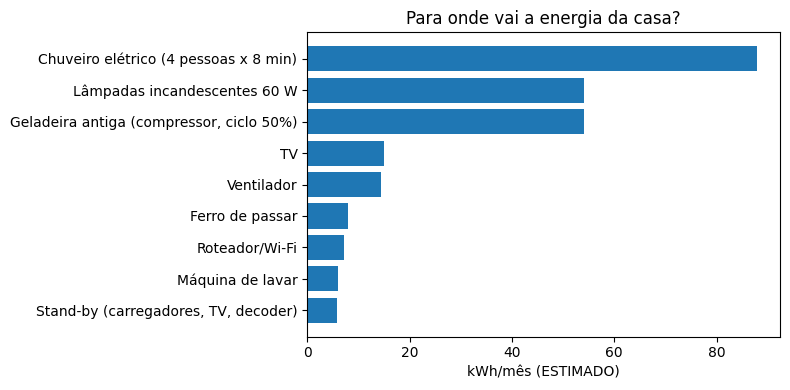

In [ ]:
d = equip.sort_values("kWh_mes")
plt.figure(figsize=(8,4))
plt.barh(d.equipamento, d.kWh_mes)
plt.xlabel("kWh/mês (ESTIMADO)"); plt.title("Para onde vai a energia da casa?")
plt.tight_layout(); plt.show()

## 3. Cálculos das alternativas

**Fórmulas usadas**
- Energia: `E (kWh) = P (kW) × t (h)`
- Geração FV mensal: `E = kWp × HSP × PR × dias`
- Dimensionamento: `kWp = (consumo − custo de disponibilidade) / (HSP × PR × dias)` (abatimento máximo = consumo − mínimo faturável)
- Economia mensal FV: `kWh abatidos × tarifa × fator de compensação`
- Retorno (*payback*): ano em que o fluxo de caixa acumulado fica ≥ 0.

In [ ]:
# ---------- Alternativa A: eficiência e uso consciente ----------
eqA = equip.copy()
eqA.loc[eqA.equipamento.str.startswith("Chuveiro"), "horas_dia"] *= (1-REDUCAO_BANHO)
m = eqA.equipamento.str.startswith("Lâmpadas"); eqA.loc[m, "potencia_W"] = LED_W
m = eqA.equipamento.str.startswith("Stand-by"); eqA.loc[m, "potencia_W"] = STANDBY_NOVO
eqA["kWh_mes"] = kwh_mes(eqA)

CONSUMO_A   = eqA.kWh_mes.sum()
INVEST_A    = 6*LED_CUSTO + REGUA_CUSTO
ECON_KWH_A  = CONSUMO_BASE - CONSUMO_A
ECON_RS_A   = ECON_KWH_A*TARIFA

# ---------- Alternativa B/C: solar FV ----------
def dimensiona(consumo_kwh):
    kwp = max(0.0, (consumo_kwh - CUSTO_DISP) / (HSP*PR*DIAS_MES))
    return round(kwp*2)/2 if kwp>0 else 0.0   # arredonda a 0,5 kWp (múltiplos de módulo aprox.)

def solar(consumo_kwh):
    kwp   = dimensiona(consumo_kwh)
    gera  = kwp*HSP*PR*DIAS_MES
    abat  = min(gera, max(0, consumo_kwh-CUSTO_DISP))
    return dict(kwp=kwp, geracao=gera, abatido=abat,
                invest=kwp*CUSTO_KWP, econ_rs=abat*TARIFA*FATOR_COMP)

SB = solar(CONSUMO_BASE)          # B: solar sobre consumo atual
SC = solar(CONSUMO_A)             # C: eficiência primeiro, solar menor depois

def fluxo(invest, econ_mes, anos=ANOS, reaj=REAJUSTE_TAR, deg=0.0, troca=False):
    ac, cum, ano_pb = [], -invest, None
    for a in range(1, anos+1):
        econ_ano = econ_mes*12*((1+reaj)**(a-1))*((1-deg)**(a-1))
        cum += econ_ano
        if troca and a==TROCA_INV_ANO: cum -= TROCA_INV_PCT*invest
        ac.append(cum)
        if ano_pb is None and cum>=0:
            prev = ac[-2] if a>1 else -invest
            ano_pb = (a-1) + (-prev)/(cum-prev)
    return np.array(ac), ano_pb

res = {}
cenarios = {
 "Situação atual":   dict(consumo=CONSUMO_BASE, invest=0, econ_kwh=0, econ_rs=0, kwp=0, fl=None),
 "A) Eficiência":    dict(consumo=CONSUMO_A, invest=INVEST_A, econ_kwh=ECON_KWH_A, econ_rs=ECON_RS_A, kwp=0, deg=0.0, troca=False),
 "B) Solar":         dict(consumo=CONSUMO_BASE-SB["abatido"], invest=SB["invest"], econ_kwh=SB["abatido"], econ_rs=SB["econ_rs"], kwp=SB["kwp"], deg=DEGRADACAO, troca=True),
 "C) A + Solar":     dict(consumo=CONSUMO_A-SC["abatido"], invest=INVEST_A+SC["invest"], econ_kwh=ECON_KWH_A+SC["abatido"], econ_rs=ECON_RS_A+SC["econ_rs"], kwp=SC["kwp"], deg=DEGRADACAO, troca=True),
}
rows=[]
for nome,c in cenarios.items():
    if nome=="Situação atual":
        rows.append([nome,0,CONSUMO_BASE,0,0,0,np.nan,0,0]); continue
    ac, pb = fluxo(c["invest"], c["econ_rs"], deg=c["deg"], troca=c["troca"])
    c["ac"], c["pb"] = ac, pb
    # CO2 (kg/mês): evitado na rede menos emissão de ciclo de vida da geração FV
    if nome.startswith("A"):
        co2 = c["econ_kwh"]*FE_REDE
    elif nome.startswith("B"):
        co2 = SB["abatido"]*(FE_REDE-FE_FV_CICLO)
    else:
        co2 = ECON_KWH_A*FE_REDE + SC["abatido"]*(FE_REDE-FE_FV_CICLO)
    c["co2"]=co2
    rows.append([nome, c["kwp"], c["consumo"], c["econ_kwh"], c["econ_rs"], c["invest"], pb, ac[-1], co2*12])

comp = pd.DataFrame(rows, columns=["Cenário","kWp","Consumo faturado (kWh/mês)","Economia (kWh/mês)",
                                   "Economia (R$/mês)","Investimento (R$)","Payback (anos)",
                                   f"Saldo acumulado em {ANOS} anos (R$)","CO2 evitado líquido (kg/ano)"])
comp

,Cenário,kWp,Consumo faturado (kWh/mês),Economia (kWh/mês),Economia (R$/mês),Investimento (R$),Payback (anos),Saldo acumulado em 25 anos (R$),CO2 evitado líquido (kg/ano)
0,Situação atual,0.00,252.36,0.00,0.00,0.00,NaN,0.00,0.00
1,A) Eficiência,0.00,179.42,72.94,75.13,88.00,0.10,"37,457.39",33.70
2,B) Solar,2.00,51.12,201.24,185.51,"9,000.00",3.85,"76,398.19",-6.04
3,C) A + Solar,1.50,30.00,222.36,212.87,"6,838.00",2.60,"91,572.72",29.22


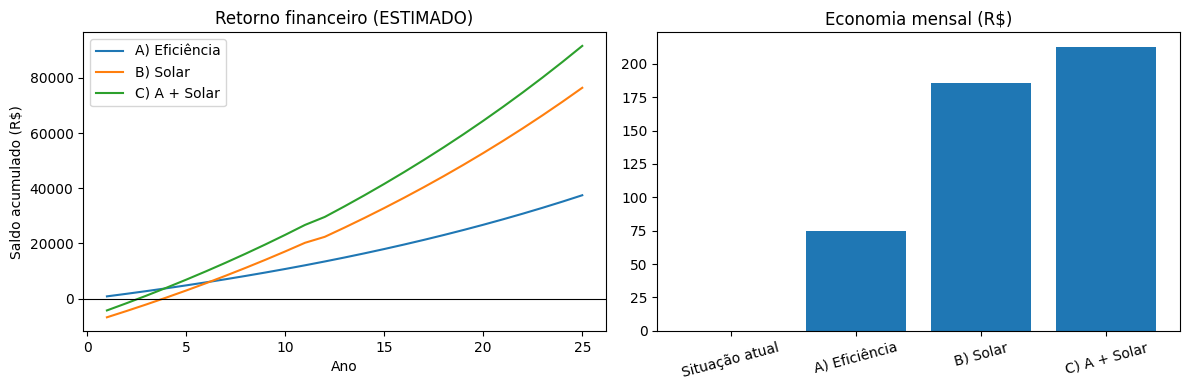

In [ ]:
fig, ax = plt.subplots(1,2, figsize=(12,4))
for nome,c in cenarios.items():
    if "ac" in c: ax[0].plot(range(1,ANOS+1), c["ac"], label=nome)
ax[0].axhline(0,color="k",lw=.8); ax[0].set_xlabel("Ano"); ax[0].set_ylabel("Saldo acumulado (R$)")
ax[0].set_title("Retorno financeiro (ESTIMADO)"); ax[0].legend()
ax[1].bar(comp["Cenário"], comp["Economia (R$/mês)"]); ax[1].set_title("Economia mensal (R$)")
plt.setp(ax[1].get_xticklabels(), rotation=15); plt.tight_layout(); plt.show()

### Análise de sensibilidade (o resultado depende das premissas)

In [ ]:
# Como o payback da alternativa B (solar) muda com tarifa [R$/kWh] e custo por kWp [R$/kWp] (premissas ESTIMADAS)
tarifas = [0.85, TARIFA, 1.20]
custos  = [2500, 4500, 6500]   # 2.500 = média nacional (Solfácil) | 6.500 = faixa alta p/ sistemas de 1,5-3 kWp
tab = pd.DataFrame(index=[f"Tarifa R$ {t:.2f}" for t in tarifas], columns=[f"R$ {c:,.0f}/kWp" for c in custos], dtype=float)
for t in tarifas:
    for cst in custos:
        kwp = SB["kwp"]; inv = kwp*cst
        econ = SB["abatido"]*t*FATOR_COMP
        _, pb = fluxo(inv, econ, deg=DEGRADACAO, troca=True)
        tab.loc[f"Tarifa R$ {t:.2f}", f"R$ {cst:,.0f}/kWp"] = pb if pb else np.nan
print("Payback da solar (anos) — NaN = não se paga em 25 anos")
tab

Payback da solar (anos) — NaN = não se paga em 25 anos


,"R$ 2,500/kWp","R$ 4,500/kWp","R$ 6,500/kWp"
Tarifa R$ 0.85,2.64,4.60,6.43
Tarifa R$ 1.03,2.20,3.85,5.40
Tarifa R$ 1.20,1.90,3.33,4.70


## 4. Justificativa das recomendações (custos, viabilidade e impacto ambiental)

1. **Começar pela eficiência (A):** investimento muito baixo, retorno em poucos meses e sem depender de telhado, financiamento ou autorização da distribuidora. Maior alvo: **chuveiro elétrico** (maior fatia do consumo) e **lâmpadas**.
2. **Solar fotovoltaica (B/C):** reduz bastante a conta no longo prazo, mas exige **investimento inicial alto**, telhado adequado (orientação/sombreamento), aprovação da distribuidora e, para quem **aluga**, a decisão não é do morador. Dimensionar **depois** da eficiência (C) evita comprar um sistema maior que o necessário.
3. **Impacto ambiental:** o fator médio da rede brasileira é muito baixo (0,0385 kgCO₂/kWh em 2023, MCTI), da ordem das emissões de ciclo de vida da própria solar (~0,041 kgCO₂e/kWh, estimado). Logo, o **ganho climático líquido da solar é próximo de zero** (pode ser ligeiramente negativo), e o ganho da eficiência é pequeno em kg de CO₂. O benefício principal é **financeiro e de resiliência** — o assistente deve dizer isso com honestidade.
4. **Limitações:** valores são **estimativas, não garantias**; dependem da tarifa/bandeira, do custo real do orçamento, do clima, dos hábitos e das regras da Lei 14.300/2022.

## 5. Integração ao Citizen Assist AI (assistente)

In [ ]:
def _norm(s):
    s = unicodedata.normalize("NFD", s.lower())
    return "".join(ch for ch in s if unicodedata.category(ch)!="Mn")

REFERENCIAS = [
 "ANEEL — Resolução Normativa nº 1.000/2021 (custo de disponibilidade) e reajuste tarifário Enel SP 2026 (efeito médio 10,18%): https://cenarioenergia.com.br/2026/06/30/aneel-aprova-reajuste-da-enel-sao-paulo-com-efeito-medio-de-1018/ (acesso 12/11/2026)",
 "Fatura pública Enel SP, residencial monofásica, 262 kWh, ago/2025 (TUSD e TE): https://www.camara.leg.br/cota-parlamentar/documentos/publ/3657/2025/8003771.pdf (acesso 12/11/2026)",
 "Fatura pública Enel SP, monofásica, consumo de 30 kWh (mínimo faturável): https://www6g.senado.leg.br/transparencia/sen/download/ceaps/documento/263575 (acesso 12/11/2026)",
 "BRASIL — Lei nº 14.300/2022 (micro e minigeração distribuída; escalonamento do Fio B, 60% em 2026): https://www.planalto.gov.br ; resumo de 2026 em https://monitordomercado.com.br/economia-2/399791-quanto-custa-instalar-energia-solar-em-uma-casa-pequena-em-2026-e-quando-a-conta-de-luz-ainda-nao-compensa-o-investimento/ (acesso 12/11/2026)",
 "CRESESB/CEPEL — SunData (irradiação solar por coordenada): https://cresesb.cepel.br/sundata/index.php ; INPE/LABREN — Atlas Brasileiro de Energia Solar (2ª ed., 2017); material de curso USP (AMT de São Paulo): https://edisciplinas.usp.br/mod/resource/view.php?id=4094581",
 "Preço de sistemas FV: Solfácil Radar 3T/2025 e 1T/2026 (R$ 2,45–2,57/Wp): https://cenarioenergia.com.br/2025/11/04/preco-da-energia-solar-sobe-1-no-3o-trimestre-mas-setor-mantem-competitividade-e-atratividade-aponta-solfacil/ ; Greener — Estudo Estratégico GD 2025 (4 kWp = R$ 11.360), via Olhar Digital: https://olhardigital.com.br/curiosidades/?p=10663",
 "MCTI/SIRENE — Fator médio de emissão do SIN (2023: 0,0385 tCO2/MWh): https://www.gov.br/mcti/pt-br/acompanhe-o-mcti/noticias/2024/02/fator-de-emissao-de-co2-na-geracao-de-energia-eletrica-no-brasil-em-2023-e-o-menor-em-12-anos ; fatores mensais 2025: https://cenarioenergia.com.br/2025/06/13/brasil-reduz-intensidade-de-carbono-na-geracao-eletrica-com-inclusao-de-novas-renovaveis-na-base-de-calculo-oficial/",
 "Potências típicas de aparelhos (dados Procel/INMETRO): https://valorfinal.com.br/tabela-potencia-aparelhos ; casa-modelo de consumo: https://valorfinal.com.br/guia/como-economizar-energia-em-casa",
 "IPCC AR5 WGIII (2014), Anexo III — emissões de ciclo de vida de tecnologias de geração: https://www.ipcc.ch (conferir valor mediano de FV usado)",
]
AVISO = ("⚠️ Estimativas com premissas (tarifa R$ {t:.2f}/kWh, {h} h de sol pleno, perfil típico de 4 pessoas). "
         "Não são valores garantidos: confira sua conta de luz e peça orçamentos.").format(t=TARIFA, h=HSP)

def _top3():
    t = equip.sort_values("kWh_mes", ascending=False).head(3)
    return "; ".join(f"{r.equipamento.split('(')[0].strip()} ({r.kWh_mes:.0f} kWh, {r['%']:.0f}%)" for _,r in t.iterrows())

def responder(pergunta):
    q = _norm(pergunta)
    A, B, C = cenarios["A) Eficiência"], cenarios["B) Solar"], cenarios["C) A + Solar"]
    def has(*ks): return any(k in q for k in ks)

    if has("referenc","fonte","de onde","base"):
        return "📚 Fontes usadas:\n- " + "\n- ".join(REFERENCIAS)
    if has("premissa","origem dos dados","dados usados","de onde vem"):
        return ("🧾 Origem dos números: tarifa R$ {t:.2f}/kWh (fatura pública Enel SP ago/2025 × reajuste ANEEL 2026 de 10,18%) [calculado]; "
                "custo mínimo 30 kWh (ANEEL) [público]; fator de emissão 0,0385 kgCO₂/kWh (MCTI 2023) [público]; "
                "Fio B 60% em 2026 (Lei 14.300) [público]; horas de sol {h} kWh/m².dia, custo do sistema R$ {c:,.0f}/kWp e consumo dos aparelhos "
                "[estimados]; hábitos de uso [hipóteses].").format(t=TARIFA, h=HSP, c=CUSTO_KWP)
    if has("garant","certeza","limit","confiav","erro"):
        return ("Limitações: o consumo do perfil é estimado; tarifa, bandeira, custo do sistema e clima variam; "
                "a Lei 14.300 altera a compensação de energia injetada; o retorno muda com reajustes. "
                "Use como ponto de partida, não como promessa.\n" + AVISO)
    if has("chuveiro","banho"):
        r = equip[equip.equipamento.str.startswith("Chuveiro")].iloc[0]
        eco = r.kWh_mes*REDUCAO_BANHO
        return (f"🚿 O chuveiro elétrico é o maior gasto: ~{r.kWh_mes:.0f} kWh/mês (~R$ {r['R$_mes']:.0f}). "
                f"Reduzir o banho em {REDUCAO_BANHO*100:.0f}% (ex.: 8→6 min) economiza ~{eco:.0f} kWh (~R$ {eco*TARIFA:.0f}/mês), de graça. "
                "Use a posição 'verão' quando possível.\n" + AVISO)
    if has("lampada","led","iluminacao"):
        r = equip[equip.equipamento.str.startswith("Lâmpadas")].iloc[0]
        novo = r.qtd*LED_W/1000*r.horas_dia*r.dias_mes
        eco = r.kWh_mes-novo
        return (f"💡 Trocar {int(r.qtd)} lâmpadas incandescentes por LED: de ~{r.kWh_mes:.0f} para ~{novo:.0f} kWh/mês, "
                f"economia ~R$ {eco*TARIFA:.0f}/mês. Custo ~R$ {r.qtd*LED_CUSTO:.0f} → se paga em cerca de {r.qtd*LED_CUSTO/(eco*TARIFA):.1f} mês(es).\n" + AVISO)
    if has("standby","stand-by","tomada","carregador"):
        r = equip[equip.equipamento.str.startswith("Stand-by")].iloc[0]
        return (f"🔌 Aparelhos em stand-by gastam ~{r.kWh_mes:.0f} kWh/mês. Com régua com chave (~R$ {REGUA_CUSTO:.0f}), "
                f"o consumo cai para ~{STANDBY_NOVO*24*DIAS_MES/1000:.1f} kWh.\n" + AVISO)
    if has("solar","painel","fotovolt","renovav","placa"):
        return (f"☀️ Solar fotovoltaica para sua casa (consumo atual): ~{B['kwp']:.1f} kWp, geração ~{SB['geracao']:.0f} kWh/mês, "
                f"investimento ~R$ {B['invest']:,.0f}, economia ~R$ {B['econ_rs']:.0f}/mês, retorno em ~{B['pb']:.1f} anos (vida útil ~{ANOS} anos). "
                f"Se fizer a eficiência antes, o sistema cai para ~{C['kwp']:.1f} kWp (R$ {SC['invest']:,.0f}). "
                "Requer telhado adequado, aprovação da distribuidora e, se alugado, acordo com o proprietário.\n" + AVISO)
    if has("retorno","payback","compensa","quanto tempo","vale a pena"):
        return (f"⏱️ Retorno estimado: A) Eficiência ~{A['pb']*12:.1f} meses; B) Solar ~{B['pb']:.1f} anos; "
                f"C) Eficiência + solar menor ~{C['pb']:.1f} anos. Recomendação: comece por A e avalie solar depois.\n" + AVISO)
    if has("co2","carbono","ambient","emissao","meio ambiente","sustent"):
        return (f"🌱 CO₂ evitado líquido (kg/ano): A) {A['co2']*12:.0f}; B) {B['co2']*12:.0f}; C) {C['co2']*12:.0f}. "
                "Como a rede elétrica brasileira já é muito limpa (0,0385 kgCO₂/kWh, MCTI 2023), o ganho climático é pequeno e, para a solar, "
                "praticamente nulo (a fabricação dos painéis emite algo parecido). O ganho principal é na conta de luz.\n" + AVISO)
    if has("consumo","gasta","gasto","conta","quanto"):
        return (f"📊 Perfil estimado: ~{CONSUMO_BASE:.0f} kWh/mês (~R$ {CUSTO_BASE:.0f}). Maiores gastos: {_top3()}.\n" + AVISO)
    if has("economi","reduzir","dica","o que fazer","comecar"):
        return (f"✅ Plano sugerido: 1) banho 25% mais curto; 2) LED; 3) régua anti stand-by → economia ~{A['econ_kwh']:.0f} kWh "
                f"(~R$ {A['econ_rs']:.0f}/mês) por ~R$ {A['invest']:.0f}. 4) Depois, avaliar solar.\n" + AVISO)
    return ("Posso ajudar com: consumo da casa, chuveiro, lâmpadas LED, stand-by, energia solar, retorno financeiro, "
            "impacto ambiental, limitações e referências. Exemplo: 'Quanto gasta meu chuveiro?'")

for p in ["Quanto eu gasto de energia?", "O chuveiro gasta muito?", "Vale a pena instalar painel solar?", "Quais as referências?"]:
    print("👤", p); print("🤖", responder(p), "\n")

👤 Quanto eu gasto de energia?
🤖 📊 Perfil estimado: ~252 kWh/mês (~R$ 260). Maiores gastos: Chuveiro elétrico (88 kWh, 35%); Lâmpadas incandescentes 60 W (54 kWh, 21%); Geladeira antiga (54 kWh, 21%).
⚠️ Estimativas com premissas (tarifa R$ 1.03/kWh, 4.3 h de sol pleno, perfil típico de 4 pessoas). Não são valores garantidos: confira sua conta de luz e peça orçamentos. 

👤 O chuveiro gasta muito?
🤖 🚿 O chuveiro elétrico é o maior gasto: ~88 kWh/mês (~R$ 91). Reduzir o banho em 25% (ex.: 8→6 min) economiza ~22 kWh (~R$ 23/mês), de graça. Use a posição 'verão' quando possível.
⚠️ Estimativas com premissas (tarifa R$ 1.03/kWh, 4.3 h de sol pleno, perfil típico de 4 pessoas). Não são valores garantidos: confira sua conta de luz e peça orçamentos. 

👤 Vale a pena instalar painel solar?
🤖 ☀️ Solar fotovoltaica para sua casa (consumo atual): ~2.0 kWp, geração ~201 kWh/mês, investimento ~R$ 9,000, economia ~R$ 186/mês, retorno em ~3.8 anos (vida útil ~25 anos). Se fizer a eficiência antes, o si

In [ ]:
# Modo interativo (descomente para conversar no Colab; digite 'sair' para encerrar)
# while True:
#     p = input("Você: ")
#     if _norm(p).strip() in ("sair","exit"): break
#     print("Assistente:", responder(p), "\n")

## 6. Testes com usuários



In [ ]:
testes = pd.DataFrame([
  ["Participante 1", "[Quanto gasta o chuveiro elétrico e como economizar?]", "[5]", "[5]", "[Achou excelente e direto ao ponto. Comentou que a família costuma tomar banhos longos e não sabia o impacto exato em reais.]", "[Nenhum ajuste necessário; entedeu foco no chuveiro como principal vilão.]"],
  ["Participante 2", "[Vale a pena instalar painel solar sendo inquilino em casa alugada?]", "[4]", "[5]", "[O participante entendeu bem as limitações, mas sugeriu que o assistente deixasse mais claro no início que o proprietário precisa autorizar e arcar com a obra.]", "[Deixei mais claro que precisa de autorização do dono.]"],
  ["Participante 3", "[Como funcionam as lâmpadas LED comparadas às incandescentes antigas?]", "[5]", "[5]", "[Achou a conta muito simples e rápida..]", "[Nenhum ajuste.]"],
], columns=["Participante (anônimo)","Situação testada","Compreensão","Utilidade","Comentário","Ajuste feito"])
testes

,Participante (anônimo),Situação testada,Compreensão,Utilidade,Comentário,Ajuste feito
0,Participante 1,[Quanto gasta o chuveiro elétrico e como econo...,[5],[5],[Achou excelente e direto ao ponto. Comentou q...,[Nenhum ajuste necessário; entedeu foco no chu...
1,Participante 2,[Vale a pena instalar painel solar sendo inqui...,[4],[5],"[O participante entendeu bem as limitações, ma...",[Deixei mais claro que precisa de autorização ...
2,Participante 3,[Como funcionam as lâmpadas LED comparadas às ...,[5],[5],[Achou a conta muito simples e rápida..],[Nenhum ajuste.]


## 7. Gerar arquivos do repositório (README, dados, cálculos, referências, testes, entrega)

In [ ]:
OUT = "citizen_assist_energia"
os.makedirs(f"{OUT}/dados", exist_ok=True); os.makedirs(f"{OUT}/testes", exist_ok=True)

equip.to_csv(f"{OUT}/dados/consumo_estimado.csv", index=False)
premissas.to_csv(f"{OUT}/dados/premissas_origem.csv", index=False)
comp.to_csv(f"{OUT}/dados/comparacao_alternativas.csv", index=False)
tab.to_csv(f"{OUT}/dados/sensibilidade_payback_solar.csv")
testes.to_csv(f"{OUT}/testes/registro_testes_usuarios.csv", index=False)
json.dump(dict(DIAS_MES=DIAS_MES,TARIFA=TARIFA,CUSTO_DISP=CUSTO_DISP,HSP=HSP,PR=PR,CUSTO_KWP=CUSTO_KWP,
               FATOR_COMP=FATOR_COMP,DEGRADACAO=DEGRADACAO,REAJUSTE_TAR=REAJUSTE_TAR,FE_REDE=FE_REDE,FE_FV_CICLO=FE_FV_CICLO),
          open(f"{OUT}/dados/premissas.json","w"), indent=2, ensure_ascii=False)
open(f"{OUT}/REFERENCIAS.md","w").write("# Referências\n\n" + "\n".join(f"- {r}" for r in REFERENCIAS) + "\n")

readme = f'''# Citizen Assist AI — Módulo de Energia e Sustentabilidade
Contribuição da disciplina **Soluções em Energias Renováveis e Sustentáveis** (Global Solution 2026 — CC 1CC).

## Integrantes
- [NOME COMPLETO — RM]
- [NOME COMPLETO — RM]
- [NOME COMPLETO — RM]

## Público e problema
Famílias de baixa renda em moradias urbanas na Grande SP (4 pessoas, ligação monofásica) que querem reduzir a conta de luz.
O assistente explica onde a energia é gasta e compara medidas por custo, viabilidade e impacto ambiental.

## Funcionalidades de energia
- Consumo por equipamento (E = P × t) e custo mensal.
- Comparação A) Eficiência, B) Solar fotovoltaica, C) A + Solar — com payback, economia e CO₂.
- Análise de sensibilidade (tarifa × custo por kWp).
- Chatbot (`responder()`) que usa os resultados calculados, cita referências e informa limitações.

## Dados e premissas (origem, unidade, período, classificação)
{premissas.round(4).to_markdown(index=False)}

## Resultados (estimados)
{comp.round(2).to_markdown(index=False)}

## Como executar
Abrir `citizen_assist_energia.ipynb` no Google Colab → Ambiente de execução → Executar tudo.

## Estrutura
- `dados/` — consumo estimado, `premissas_origem.csv` (origem, unidade, período e classificação de cada dado), comparação e sensibilidade
- `REFERENCIAS.md` — fontes
- `testes/` — registro dos testes com usuários e ajustes

## Limitações
Valores de consumo, tarifa, custos, irradiação e emissões são **estimativas** e não representam garantia de economia ou geração.
'''
open(f"{OUT}/README.md","w").write(readme)

open(f"{OUT}/entrega.txt","w").write('''Integrantes:
- Nome completo - RM
- Nome completo - RM
- Nome completo - RM

Repositório GitHub: https://github.com/[usuario]/[repositorio]
Vídeo YouTube (não listado): https://youtu.be/[id]
''')
print(os.listdir(OUT))
try:
    from google.colab import files
    import shutil; shutil.make_archive(OUT, "zip", OUT); files.download(OUT+".zip")
except Exception:
    pass

['REFERENCIAS.md', 'dados', 'testes', 'README.md', 'entrega.txt']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>